
# Evaluación de Segunda Unidad: Clasificación de imágenes con CNN

**Curso:** Inteligencia Artificial  
**Dataset:** CIFAR-10  
**Semilla aleatoria:** 73

## Objetivo

Explorar el conjunto de datos CIFAR-10, visualizar imágenes, analizar la distribución de clases y comprobar el funcionamiento de una red neuronal convolucional (CNN).


In [1]:

import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision import datasets

sys.path.insert(0, str(Path.cwd().parent / "src"))

SEED = 73
torch.manual_seed(SEED)
np.random.seed(SEED)

print("PyTorch:", torch.__version__)
print("Semilla:", SEED)
print("Notebook preparado correctamente.")


PyTorch: 2.15.0+cpu
Semilla: 73
Notebook preparado correctamente.


In [2]:

dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True
)

clases = dataset.classes

print("Cantidad de imágenes:", len(dataset))
print("Cantidad de clases:", len(clases))
print("Clases:", clases)
print("Dimensiones de una imagen:", dataset[0][0].size)


100.0%


Cantidad de imágenes: 50000
Cantidad de clases: 10
Clases: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Dimensiones de una imagen: (32, 32)


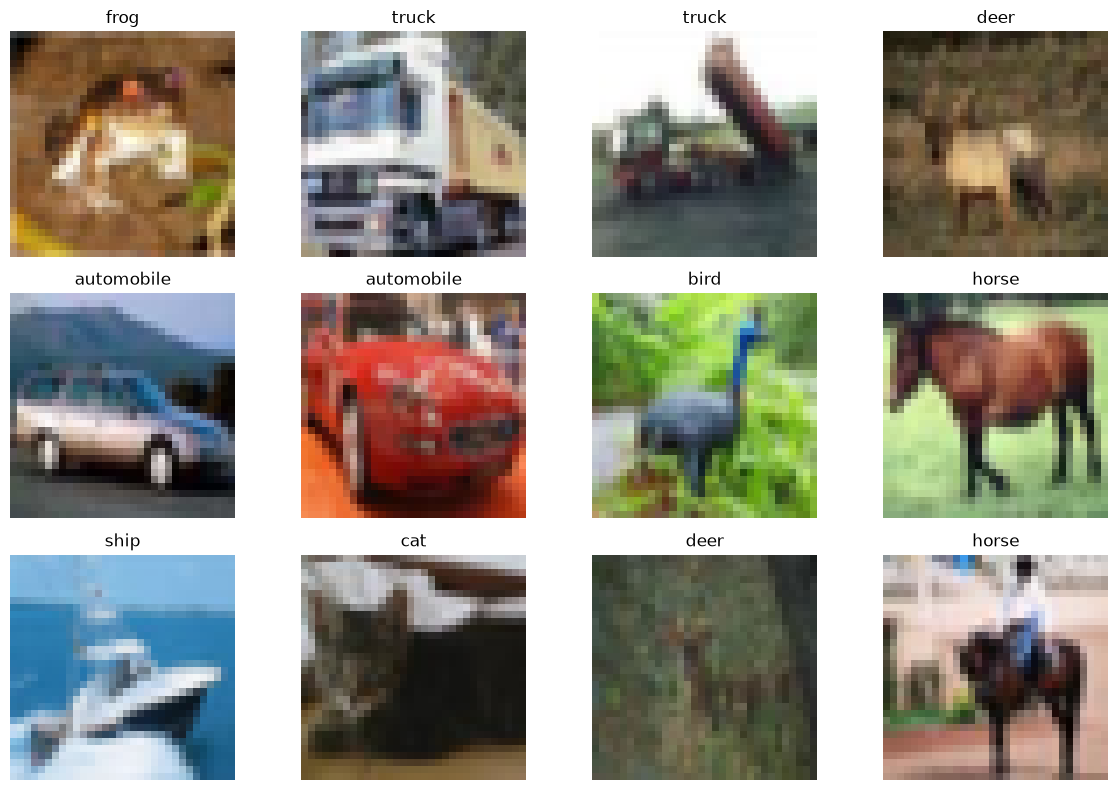

In [3]:

fig, axes = plt.subplots(3, 4, figsize=(12, 8))

for i, ax in enumerate(axes.flat):
    imagen, etiqueta = dataset[i]
    ax.imshow(imagen)
    ax.set_title(clases[etiqueta])
    ax.axis("off")

plt.tight_layout()
plt.show()


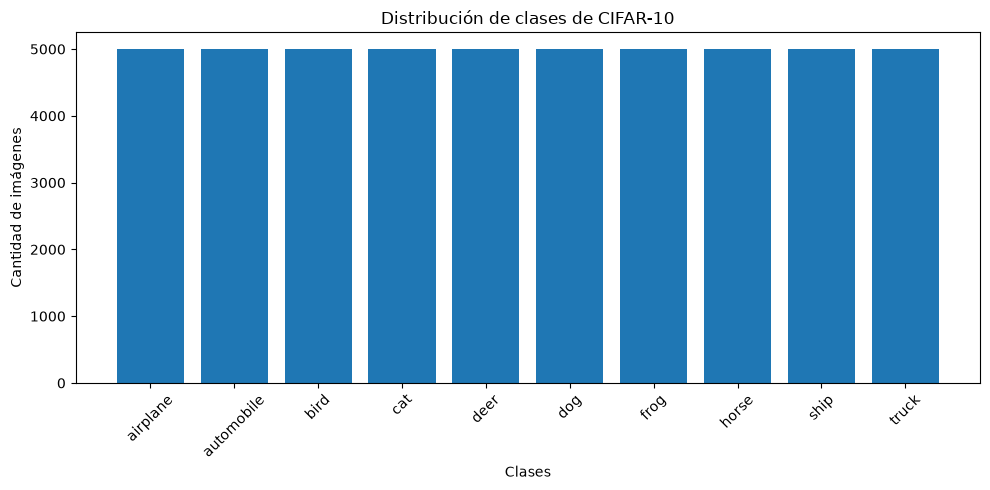

Imágenes por clase: [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


In [4]:

etiquetas = np.array(dataset.targets)
conteos = np.bincount(etiquetas, minlength=10)

plt.figure(figsize=(10, 5))
plt.bar(clases, conteos)
plt.title("Distribución de clases de CIFAR-10")
plt.xlabel("Clases")
plt.ylabel("Cantidad de imágenes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Imágenes por clase:", conteos)


In [5]:

from dataset import get_loaders

train_loader, val_loader, test_loader = get_loaders()

imagenes, etiquetas_lote = next(iter(train_loader))

print("Forma del lote de imágenes:", imagenes.shape)
print("Forma del lote de etiquetas:", etiquetas_lote.shape)
print("Lotes de entrenamiento:", len(train_loader))
print("Lotes de validación:", len(val_loader))
print("Lotes de prueba:", len(test_loader))



===== DIMENSIONES DE CIFAR-10 =====
Imágenes originales de entrenamiento: 50000
Imágenes para entrenamiento: 40000
Imágenes para validación: 10000
Imágenes para prueba: 10000

===== DIMENSIONES DE LOS LOTES =====
Forma de las imágenes: torch.Size([64, 3, 32, 32])
Forma de las etiquetas: torch.Size([64])
Forma del lote de imágenes: torch.Size([64, 3, 32, 32])
Forma del lote de etiquetas: torch.Size([64])
Lotes de entrenamiento: 625
Lotes de validación: 157
Lotes de prueba: 157


In [6]:

from model import CNN

modelo = CNN()
lote_prueba = torch.randn(4, 3, 32, 32)

with torch.no_grad():
    salida = modelo(lote_prueba)

print("Entrada:", lote_prueba.shape)
print("Salida:", salida.shape)

assert salida.shape == (4, 10)
print("Prueba del modelo superada correctamente.")


Entrada: torch.Size([4, 3, 32, 32])
Salida: torch.Size([4, 10])
Prueba del modelo superada correctamente.



## Interpretación

1. CIFAR-10 contiene imágenes RGB de 32 × 32 píxeles distribuidas en diez clases.
2. La visualización permite reconocer ejemplos de las categorías del conjunto de datos.
3. El gráfico permite comprobar la distribución de imágenes por clase.
4. Un lote con forma [64, 3, 32, 32] representa 64 imágenes, tres canales de color y dimensiones de 32 × 32 píxeles.
5. La CNN debe producir una salida de forma [4, 10] cuando recibe cuatro imágenes, porque clasifica cada imagen entre diez categorías.
